# qins: Getting Started

**Multi-agent benchmark of quantum simulations of inelastic neutron scattering (INS).**

This notebook walks through the codebase from the physics to a full pipeline run. Every number and figure
below is computed by code in this repository when you run the notebook.

| Part | What you will see |
|---|---|
| 1 | The scientific problem: what the pipeline computes and why |
| 2 | Models and conventions (`qins/physics/models.py`) |
| 3 | The physics building blocks, run by hand on a small chain: ground state, HVA, kick, Trotter, S(q, w) |
| 4 | The agent DAG: how the 11 agents are scheduled (`qins/dag.py`) |
| 5 | One full pipeline run and what it leaves on disk |
| 6 | Reading the results: spectra, benchmark metrics, decisions |
| 7 | Error-mitigation selection and the optional LLM |
| 8 | How to extend, test and cite |

## 1. The problem

Inelastic neutron scattering measures the **dynamical structure factor** $S(q,\omega)$ of a magnet. For a spin chain it
tells us which spin excitations (spinons, solitons, ...) exist at each momentum $q$ and energy $\omega$.

A quantum computer can estimate $S(q,\omega)$ following the IBM tutorial
([simulate-neutron-scattering](https://quantum.cloud.ibm.com/docs/en/tutorials/simulate-neutron-scattering), arXiv:2603.15608):

1. Prepare the ground state $|GS\rangle$ with a variational circuit (HVA).
2. Apply a small **kick** $R_z(\pi/2)$ on a centre site. This mimics the neutron flipping a spin.
3. Evolve in time with Trotter steps, measure $\langle Z_j(t)\rangle$ on every site $j$.
4. The result is the retarded Green's function $G^R(j,t)$. Fourier transform in time and space to get $S(q,\omega)$.

Circuits get deep quickly, so the first few time steps are **compressed** with approximate quantum compilation (AQC).

**What `qins` adds on top of the tutorial**

* a benchmark of three sources against each other (hardware, noisy MPS, classical DMRG) and against INS data,
* four materials (XX chain, KCuF3, two-soliton chain, CsCoX3),
* calibration-aware qubit-chain selection over several IBM backends,
* per-circuit selection of error mitigation (DD, PT, TREX, ZNE),
* optional LLM extraction of Hamiltonian parameters from `Papers/`,
* a provenance log (`manifest.json`, `events.jsonl`) for every number.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

# Work from the repository root no matter where Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
os.environ.setdefault("QISKIT_PARALLEL", "FALSE")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})
print("repo root:", ROOT)

repo root: /home/pza/keerthi


## 2. Models and conventions

A model is a frozen dataclass, `SpinModel`, describing an XXZ chain with optional uniform (`hz`) and staggered (`hs`) fields:

$$H = \sum_i \Big[ J_{xy}(S^x_iS^x_{i+1}+S^y_iS^y_{i+1}) + J_z S^z_iS^z_{i+1} \Big] + \sum_i h_i S^z_i ,\qquad S=\sigma/2,\; \text{open boundaries}.$$

Conventions that every agent shares (they are also written down in `.claude/rules/dsf-assembly.md`):

* energy unit $J=1$; `energy_scale_meV` converts to meV for plots and INS comparison,
* the kicked site is `center = n_sites // 2 - 1`,
* the number of qubits must be even,
* time grid $t_m = m\,dt$ for $m=1..n_{steps}$.

In [2]:
from qins.physics.models import PRESETS, get_model

pd.DataFrame([
    {"model": k, "material": m.material, "Jxy": m.jxy, "Jz": m.jz, "hz": m.hz, "h_stag": m.hs,
     "J (meV)": m.energy_scale_meV, "what it tests": m.description}
    for k, m in PRESETS.items()
]).set_index("model")

,material,Jxy,Jz,hz,h_stag,J (meV),what it tests
model,,,,,,,
xx,XX chain (free fermions),1.00,0.0,0.0,0.00,1.0,Gapless XX chain; exactly solvable via Jordan-...
kcuf3,KCuF3,1.00,1.0,0.0,0.00,33.5,Near-ideal spin-1/2 Heisenberg chain; two-spin...
two_soliton,Ising-like XXZ chain,0.30,1.0,0.0,0.00,1.0,Gapped Ising-like chain; neutron creates a two...
cscox3,"CsCoX3 (X = Cl, Br)",0.14,1.0,0.0,0.05,13.0,Ising-like chain with staggered interchain fie...


**Regression check.** The ground-state energy of the 10-site isotropic chain must be $E_0=-4.258035207$ in these units
(the IBM tutorial's DMRG value). We check it with exact diagonalisation, then with DMRG.

In [3]:
from qins.physics.mps import dmrg

m10 = get_model("kcuf3", {"system": {"n_sites": 10}})
e_ed, _ = m10.exact_ground_state()
e_dmrg, psi_dmrg, info = dmrg(m10, chi=32)
print(f"ED     E0 = {e_ed:.9f}")
print(f"DMRG   E0 = {e_dmrg:.9f}   (chi=32, max bond reached {info['max_bond_reached']}, {info['n_sweeps']} sweeps)")
print(f"expected  = -4.258035207   |ED - expected| = {abs(e_ed + 4.258035207):.1e}")

ED     E0 = -4.258035207
DMRG   E0 = -4.258035207   (chi=32, max bond reached 20, 3 sweeps)
expected  = -4.258035207   |ED - expected| = 2.8e-10


## 3. The physics building blocks, by hand

Before looking at the agents, here is what they do, on an 8-site KCuF3 chain small enough for exact statevectors.

### 3.1 Ground-state ansatz (agent a02)

The HVA starts from nearest-neighbour singlets and applies alternating odd/even bond layers
$\exp(-i\theta\,(XX+YY+ZZ)/2)$. Each gate is SU(2) invariant, so the output is always a total-spin singlet.

In [4]:
from qins.physics.circuits import hva_ansatz

m8 = get_model("kcuf3", {"system": {"n_sites": 8}})
print(f"center site = {m8.center},  has_field = {m8.has_field}")
print(hva_ansatz(m8, layers=1).draw("text", fold=120))

center site = 3,  has_field = False
     ┌───┐┌───┐                                                ┌────────────────────────────────────┐
q_0: ┤ X ├┤ H ├──■─────────────────────────────────────────────┤0                                   ├
     └───┘└───┘┌─┴─┐┌───┐┌────────────────────────────────────┐│  exp(-it (XX + YY + ZZ))(theta[1]) │
q_1: ──────────┤ X ├┤ X ├┤0                                   ├┤1                                   ├
     ┌───┐┌───┐└───┘└───┘│  exp(-it (XX + YY + ZZ))(theta[0]) │├────────────────────────────────────┤
q_2: ┤ X ├┤ H ├──■───────┤1                                   ├┤0                                   ├
     └───┘└───┘┌─┴─┐┌───┐├────────────────────────────────────┤│  exp(-it (XX + YY + ZZ))(theta[1]) │
q_3: ──────────┤ X ├┤ X ├┤0                                   ├┤1                                   ├
     ┌───┐┌───┐└───┘└───┘│  exp(-it (XX + YY + ZZ))(theta[0]) │├────────────────────────────────────┤
q_4: ┤ X ├┤ H ├──■───────┤1                   

Optimise the angles by VQE (`COBYQA`, gradient free) and compare with the exact ground state. This is the same function agent a02 calls.

In [5]:
from qins.agents.a02_gs_ansatz import optimise_hva
from qins.physics.mps import fidelity_with_vector

rng = np.random.default_rng(12345)
e_exact, vec = m8.exact_ground_state()
rows = []
for layers in (1, 2, 3):
    r = optimise_hva(m8, layers, "singlet", {"maxiter": 150, "max_bond": 64}, rng)
    rows.append({"layers": layers, "E_HVA": r["energy"], "E_exact": e_exact,
                 "rel. energy error": (r["energy"] - e_exact) / abs(e_exact),
                 "fidelity with exact GS": fidelity_with_vector(r["circuit"], vec), "H evaluations": r["n_evals"]})
    gs_circuit = r["circuit"]          # keep the 3-layer result for later
pd.DataFrame(rows).set_index("layers").style.format({"E_HVA": "{:.4f}", "E_exact": "{:.4f}", "rel. energy error": "{:.2e}",
                                                      "fidelity with exact GS": "{:.4f}"})

,E_HVA,E_exact,rel. energy error,fidelity with exact GS,H evaluations
layers,,,,,
1,-3.2904,-3.3749,2.50e-02,0.9355,37
2,-3.3440,-3.3749,9.15e-03,0.9741,160
3,-3.3697,-3.3749,1.55e-03,0.9967,199


More layers give a better state, at the price of more two-qubit gates. This size-versus-depth trade-off is what the
`ansatz.sweep` block in the config measures (Fig. S2 of the paper).

### 3.2 Kick, Trotter evolution and the retarded Green's function

The kick is $R_z(\pi/2)=(I-iZ_c)/\sqrt2$. Expanding $\langle Z_j(t)\rangle$ after the kick gives

$$\langle Z_j\rangle_\pm(t) = A_j(t) \pm G_j(t),\qquad G_j(t)= -\tfrac{i}{2}\langle[Z_j(t),Z_c]\rangle ,$$

where $A_j$ is a non-retarded background. It vanishes only if the prepared state is symmetric under the global spin flip.
`kick_signs` decides whether one kick suffices; otherwise both signs are run and $G=(z_+-z_-)/2$.

Below we check against exact time evolution $e^{-iHt}$: the Trotter circuit should reproduce $G^R$ up to $O(dt^2)$.

In [6]:
from scipy.sparse.linalg import expm_multiply
from qiskit.quantum_info import Statevector, SparsePauliOp
from qins.physics.circuits import kick, kick_signs, trotter_circuit
from qins.physics.mps import z_profile, circuit_to_mps

n, c = m8.n_sites, m8.center
H = m8.hamiltonian().to_matrix(sparse=True)
Zops = [SparsePauliOp.from_sparse_list([("Z", [j], 1)], num_qubits=n) for j in range(n)]

def z_exact(state0, t):
    psi = expm_multiply(-1j * H * t, state0)
    return np.array([np.real(np.vdot(psi, Z.to_matrix(sparse=True) @ psi)) for Z in Zops])

def z_trotter(state0, kick_qc, dt, steps, order=2):
    qc = kick_qc.compose(trotter_circuit(m8, dt, steps, order))
    sv = Statevector(state0).evolve(qc)
    return np.real([sv.expectation_value(Z) for Z in Zops])

gs_exact = vec.astype(complex)
t_final = 2.4
rows = []
for dt in (0.6, 0.3, 0.15):
    steps = int(round(t_final / dt))
    zt = z_trotter(gs_exact, kick(m8, +1), dt, steps)
    ze = z_exact(Statevector(gs_exact).evolve(kick(m8, +1)).data, t_final)
    rows.append({"dt": dt, "steps": steps, "max |<Z_j>_Trotter - exact|": np.abs(zt - ze).max()})
err = pd.DataFrame(rows).set_index("dt")
err["ratio to previous"] = err.iloc[:, -1].shift(1) / err.iloc[:, -1]
err

,steps,max |<Z_j>_Trotter - exact|,ratio to previous
dt,,,
0.60,4,0.019253,NaN
0.30,8,0.004756,4.047902
0.15,16,0.001186,4.011913


A ratio near 4 when `dt` is halved confirms second-order Trotter error. Next: is one kick enough? We check the spin-flip symmetry of the exact and of the optimised HVA state.

In [7]:
def z_of(state):                       # <Z_j> of a state vector
    return np.real([np.vdot(state, Z.to_matrix(sparse=True) @ state) for Z in Zops])

hva_state = Statevector(gs_circuit).data
for name, st in (("exact GS", gs_exact), ("HVA (3 layers)", hva_state)):
    mz = np.abs(z_of(st)).max()
    print(f"{name:16s} max|<Z_j>| = {mz:.2e}  ->  kick signs {kick_signs(m8, mz)}")
print("Neel-like state:  max|<Z_j>| = 1.0  ->  kick signs", kick_signs(m8, 1.0))

# G from a single kick equals (z+ - z-)/2 for the P-symmetric exact ground state:
t = 1.7
zp = z_exact(Statevector(gs_exact).evolve(kick(m8, +1)).data, t)
zm = z_exact(Statevector(gs_exact).evolve(kick(m8, -1)).data, t)
print(f"\nexact GS, t={t}: max|z+ - G_two_sign| = {np.abs(zp - (zp - zm) / 2).max():.1e}   (single kick is exact)")

exact GS         max|<Z_j>| = 8.81e-16  ->  kick signs [1]
HVA (3 layers)   max|<Z_j>| = 5.55e-17  ->  kick signs [1]
Neel-like state:  max|<Z_j>| = 1.0  ->  kick signs [1, -1]

exact GS, t=1.7: max|z+ - G_two_sign| = 3.1e-15   (single kick is exact)


### 3.3 From G(j, t) to S(q, w) (agent a09)

`rgf_to_dsf` is a rectangle-rule Fourier transform in time (frequencies up to the Nyquist limit $\pi/dt$) followed by a
spatial transform around the centre site. Two options are available: a time window and Gaussian broadening that mimics instrument resolution.

For the Heisenberg chain, theory predicts that weight lies between the two-spinon edges
$\omega_L(q)=\tfrac{\pi}{2}J|\sin q|$ and $\omega_U(q)=\pi J|\sin (q/2)|$. We use a 10-site chain for a bit more resolution.

G(j,t) shape: (24, 10)  (rows: t = dt..T, columns: site j)


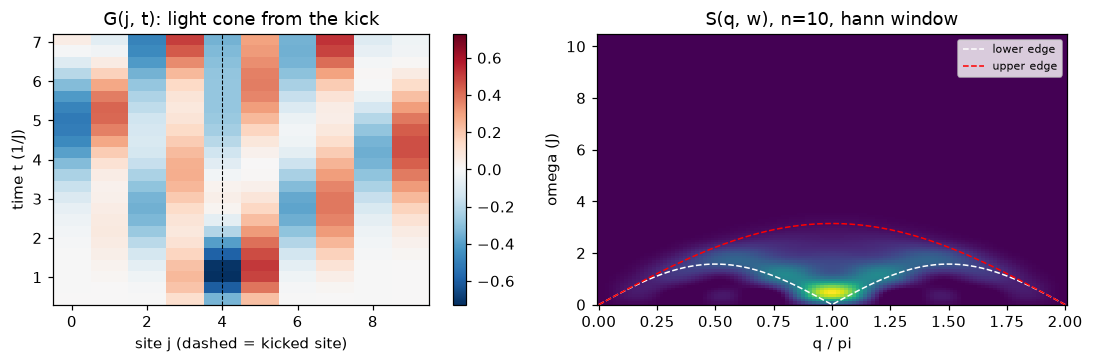

In [8]:
from qins.physics.dsf import rgf_to_dsf, rgf_from_z

n10, c10 = 10, m10.center
Z10 = [SparsePauliOp.from_sparse_list([("Z", [j], 1)], num_qubits=n10) for j in range(n10)]
_, vec10 = m10.exact_ground_state()
dt, n_steps = 0.3, 24

zs = []
for step in range(0, n_steps + 1):
    qc = kick(m10, +1).compose(trotter_circuit(m10, dt, step)) if step else kick(m10, +1)
    sv = Statevector(vec10.astype(complex)).evolve(qc)
    zs.append(np.real([sv.expectation_value(Z) for Z in Z10]))
rgf = rgf_from_z(np.array(zs)[None])           # shape (n_steps, n_sites), one kick sign
print("G(j,t) shape:", rgf.shape, " (rows: t = dt..T, columns: site j)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
im = ax[0].imshow(rgf, aspect="auto", origin="lower", cmap="RdBu_r", extent=[-.5, n10 - .5, dt, n_steps * dt],
                  vmin=-np.abs(rgf).max(), vmax=np.abs(rgf).max())
ax[0].axvline(c10, ls="--", c="k", lw=.7); ax[0].set(xlabel="site j (dashed = kicked site)", ylabel="time t (1/J)", title="G(j, t): light cone from the kick")
fig.colorbar(im, ax=ax[0])

out = rgf_to_dsf(rgf, dt, c10, n_omega=120, n_q=120, window="hann", broadening=0.15)
q, w, S = out["q"], out["omega"], out["S"]
ax[1].pcolormesh(q / np.pi, w, S / S.max(), cmap="viridis", shading="auto")
qq = np.linspace(0, 2 * np.pi, 400)
ax[1].plot(qq / np.pi, np.pi / 2 * np.abs(np.sin(qq)), "w--", lw=1, label="lower edge")
ax[1].plot(qq / np.pi, np.pi * np.abs(np.sin(qq / 2)), "r--", lw=1, label="upper edge")
ax[1].set(xlabel="q / pi", ylabel="omega (J)", title="S(q, w), n=10, hann window", ylim=(0, w[-1])); ax[1].legend(loc="upper right", fontsize=7)
plt.tight_layout(); plt.show()

Weight sits between the two-spinon edges and peaks near $q=\pi$ at low energy, as expected.
The finite window $T=n_{steps}\,dt$ limits energy resolution to about $2\pi/T$.

## 4. The agent DAG

Each agent is a small class in `qins/agents/` with four attributes: `name`, `fanout` (one task per **model**, per
**backend**, or a single task), `deps` (upstream agents) and `run(ctx)`. The scheduler expands every agent into tasks and starts
a task as soon as its own upstream tasks are done. Models therefore pipeline independently.

```
a00 model spec ──┬─> a01 MPS/DMRG ───────────────────────────────┐
  (per model)    └─> a02 GS ansatz ─> a03 AQC ─> a07 assembly ─┬─> a05 noise sweep ─┐
a04 HW calibration (per backend) ──────────────────────────────┴─> a08 HW execution ─┴─> a09 DSF ─> a10 benchmark
a06 metric self-test ─────────────────────────────────────────────────────────────────────────────────┘
```

In [9]:
from qins import load_config
from qins.agents import AGENT_REGISTRY
from qins.dag import build_tasks

cfg_default = load_config("default")
pd.DataFrame([{"agent": a.name, "title": a.title, "fan-out": a.fanout or "single", "depends on": ", ".join(d[:3] for d in a.deps) or "-"}
              for a in AGENT_REGISTRY.values()]).sort_values("agent").set_index("agent")

,title,fan-out,depends on
agent,,,
a00_model_spec,Material -> Hamiltonian specification,model,-
a01_mps_dmrg,Classical MPS/DMRG ground state + reference dy...,model,a00
a02_gs_ansatz,Ground-state ansatz (VQE / HVA),model,a00
a03_aqc,Approximate quantum compilation (tensor network),model,"a00, a02"
a04_hw_calibration,Hardware calibration + layout search,backend,-
a05_noise_model,Depolarising-channel MPS simulation sweep,model,"a00, a07"
a06_metrics,"Metric suite (MSE, Wasserstein, SSIM, nQFI, tw...",single,-
a07_assembly,Circuit assembly (GS + AQC + Trotter tail),model,"a00, a02, a03"
a08_hw_execution,Quantum hardware execution (PT / DD / TREX / ZNE),model,"a00, a07, a04"


The task graph for the default config (4 models x 3 backends) has one node per (agent, key). The layout below places each task in its dependency generation.

40 tasks, 92 dependencies


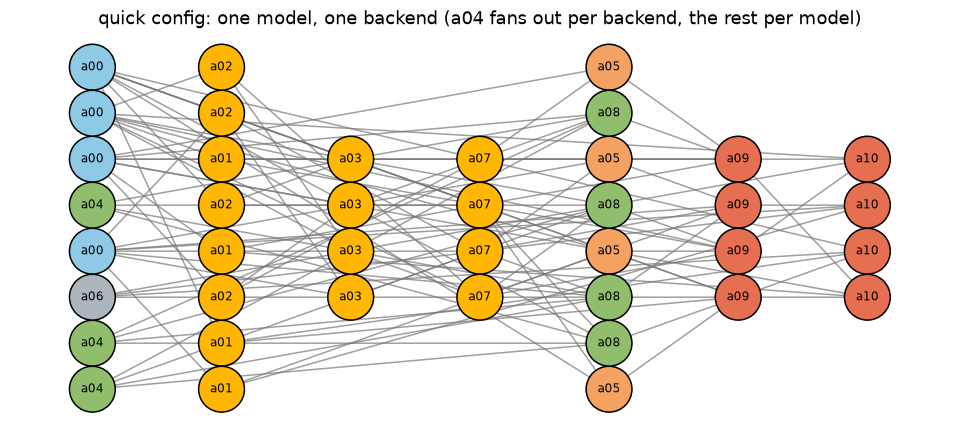

In [10]:
from qins.config import to_dict

tasks = build_tasks(to_dict(cfg_default))
G = nx.DiGraph()
for tid, t in tasks.items():
    G.add_node(tid, agent=t.agent)
    G.add_edges_from((d, tid) for d in t.deps)
print(f"{G.number_of_nodes()} tasks, {G.number_of_edges()} dependencies")

for gen, nodes in enumerate(nx.topological_generations(G)):
    for nd in nodes:
        G.nodes[nd]["gen"] = gen

# Draw the agent-level DAG for one model so the figure stays readable.
one = build_tasks(to_dict(load_config("quick")), None)
H_ = nx.DiGraph()
for tid, t in one.items():
    short = tid.split("_")[0] + ("[" + tid.split("[")[1] if "[" in tid and not tid.startswith(("a04", "a06")) else "")
    H_.add_node(tid)
    H_.add_edges_from((d, tid) for d in t.deps)
for gen, nodes in enumerate(nx.topological_generations(H_)):
    for nd in nodes:
        H_.nodes[nd]["gen"] = gen
pos = nx.multipartite_layout(H_, subset_key="gen")
colors = {"a00": "#8ecae6", "a01": "#ffb703", "a02": "#ffb703", "a03": "#ffb703", "a04": "#90be6d",
          "a05": "#f4a261", "a06": "#adb5bd", "a07": "#ffb703", "a08": "#90be6d", "a09": "#e76f51", "a10": "#e76f51"}
fig, ax = plt.subplots(figsize=(11, 4.6))
nx.draw_networkx_edges(H_, pos, ax=ax, arrows=True, arrowsize=10, edge_color="#777", alpha=.7)
nx.draw_networkx_nodes(H_, pos, ax=ax, node_size=900, node_color=[colors[t[:3]] for t in H_], edgecolors="k")
nx.draw_networkx_labels(H_, pos, ax=ax, labels={t: t[:3] for t in H_}, font_size=8)
ax.set_title("quick config: one model, one backend (a04 fans out per backend, the rest per model)"); ax.axis("off"); plt.show()

A task is cached by `config_hash` and the hashes of its upstream results, so `--resume <run_dir>` re-runs only what changed.
Each task also gets a deterministic seed derived from `run.seed` and its task id, and that seed is logged.

**Where this differs from `Agent division.pdf`** (full discussion in the README): a00 is split out, a03 depends on a02,
a05 simulates the assembled hardware circuits (so it depends on a07), and magnetised states use signed kicks.

## 5. One full pipeline run

The `quick` config runs KCuF3 on 8 sites with a short time series. Everything is configured through YAML plus dotted
overrides. The cell below prints the settings that matter, then runs the pipeline (about 30 s on a laptop CPU).

In [11]:
from qins import Pipeline

RUN_PIPELINE = True      # set False to re-use the newest existing run in runs/

cfg = load_config("quick", ["models=[kcuf3]", "hardware.backends=[ibm_kingston]", "run.name=notebook_demo"])
show = {k: to_dict(cfg)[k] for k in ("system", "dynamics", "ansatz", "aqc", "noise", "execution")}
print(json.dumps(show, indent=1, default=str)[:1500])

{
 "system": {
  "n_sites": 8
 },
 "dynamics": {
  "dt": 0.6,
  "n_steps": 6,
  "trotter_order": 2,
  "reference_substeps": 2,
  "ref_max_bond": 64,
  "symmetry_tol": 0.001
 },
 "ansatz": {
  "layers": 2,
  "inits": [
   "singlet",
   "neel"
  ],
  "optimizer": "COBYQA",
  "maxiter": 120,
  "max_bond": 64,
  "sweep": {
   "enabled": true,
   "sizes": [
    4,
    6
   ],
   "layers": [
    1,
    2
   ]
  }
 },
 "aqc": {
  "enabled": true,
  "aqc_steps": 2,
  "ansatz_steps": 1,
  "max_bond": 32,
  "cutoff": 1e-08,
  "maxiter": 20,
  "autodiff_backend": "jax"
 },
 "noise": {
  "depolarizing_rates": [
   0.005,
   0.001
  ],
  "one_qubit_ratio": 0.1,
  "shots": 1000,
  "method": "matrix_product_state"
 },
 "execution": {
  "mode": "local_emulator",
  "backend": "auto",
  "shots": 1000,
  "optimization_level": 2,
  "twirling": {
   "num_randomizations": 1000,
   "shots_per_randomization": 128
  },
  "mitigation": {
   "policy": "rules",
   "force": null,
   "thresholds": {
    "trex_reado

In [12]:
if RUN_PIPELINE:
    t0 = time.time()
    result = Pipeline(cfg).run()
    RUN = Path(result.run_dir)
    print(f"run dir: {RUN}\nstatus : {result.status}   wall time {time.time() - t0:.1f} s")
else:
    RUN = sorted((ROOT / "runs").glob("quick_*"))[-1]
    print("using existing run:", RUN)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


run dir: runs/notebook_demo_20261023_130218
status : {'ok': 11}   wall time 27.8 s


### 5.1 What a run leaves on disk

In [13]:
def tree(path, depth=0, maxdepth=2):
    for p in sorted(path.iterdir()):
        print("  " * depth + ("📁 " if p.is_dir() else "   ") + p.name)
        if p.is_dir() and depth < maxdepth - 1:
            tree(p, depth + 1, maxdepth)
tree(RUN)

   config.yaml
   dag.mmd
   events.jsonl
   manifest.json
   metrics_all.csv
   report.md
   run.log
📁 tasks
  📁 a00_model_spec[kcuf3]
  📁 a01_mps_dmrg[kcuf3]
  📁 a02_gs_ansatz[kcuf3]
  📁 a03_aqc[kcuf3]
  📁 a04_hw_calibration[ibm_kingston]
  📁 a05_noise_model[kcuf3]
  📁 a06_metrics[all]
  📁 a07_assembly[kcuf3]
  📁 a08_hw_execution[kcuf3]
  📁 a09_dsf[kcuf3]
  📁 a10_benchmark[kcuf3]


* `manifest.json` has the resolved config, package versions, host, SHA-256 of every input file, the task graph and per-task status.
* `events.jsonl` is one JSON line per event (`task_start/end`, `artifact`, `metric`, `decision`, `llm_call`, `warning`, `error`).
* `tasks/<agent>[<key>]/` has `result.json` plus the artifacts (`.npz`, `.qpy`, `.json`, `.png`).
* `report.md` and `metrics_all.csv` summarise the benchmark.

In [14]:
manifest = json.loads((RUN / "manifest.json").read_text())
pk = manifest["environment"]["packages"]
print("packages:", {k: pk[k] for k in ("qiskit", "quimb", "numpy") if k in pk}, "| host cpus:", manifest["environment"]["cpu_count"])
print("seed:", manifest["config"]["run"]["seed"], "| status:", manifest["status"], "| wall_s:", manifest["wall_s"])

rows = [{"task": tid, "status": r["status"], "seconds": r["duration_s"], "seed": r["seed"]} for tid, r in manifest["task_results"].items()]
pd.DataFrame(rows).sort_values("task").set_index("task")

packages: {'qiskit': '2.5.2', 'quimb': '1.15.0', 'numpy': '2.5.4'} | host cpus: 72
seed: 12345 | status: {'ok': 11} | wall_s: 27.68


,status,seconds,seed
task,,,
a00_model_spec[kcuf3],ok,0.588,1297976518
a01_mps_dmrg[kcuf3],ok,1.054,2194534614
a02_gs_ansatz[kcuf3],ok,3.635,1674868470
a03_aqc[kcuf3],ok,9.920,3725971599
a04_hw_calibration[ibm_kingston],ok,0.445,3680849919
a05_noise_model[kcuf3],ok,7.965,3926328085
a06_metrics[all],ok,0.478,3862251986
a07_assembly[kcuf3],ok,1.073,542112130
a08_hw_execution[kcuf3],ok,12.006,2618844279


### 5.2 Where did the time go?

In [15]:
df = pd.DataFrame(rows).sort_values("seconds")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh([t.split("[")[0] for t in df.task], df.seconds, color="#4c78a8")
ax.set(xlabel="seconds", title="Per-agent wall time (tasks overlap, so the sum exceeds the total)"); plt.tight_layout(); plt.show()

## 6. Reading the results

### 6.1 Agent by agent
Each `result.json` has a small `summary`. Here are the headline numbers from the first stages.

In [16]:
def summary(agent):
    p = next((RUN / "tasks").glob(f"{agent}*")) / "result.json"
    return json.loads(p.read_text())["summary"]

a01, a02, a03 = summary("a01"), summary("a02"), summary("a03")
print("a01 DMRG   : E0 =", round(a01["ground_energy"], 6), "| exact =", round(a01["exact_energy"], 6), "| converged chi =", a01["converged_chi"])
print("a02 ansatz : init =", a02["best_init"], "| layers =", a02["layers"], "| fidelity vs exact =", round(a02["fidelity_vs_exact"], 4),
      "| max|<Z>| =", f"{a02['max_abs_z']:.1e}", "| kick signs =", a02["kick_signs"])
print("a02 depth  :", a02["circuit_stats"])
if a03.get("enabled"):
    print("a03 AQC    : fidelities per step =", [round(f, 4) for f in a03["fidelities"]], "| n_params =", a03["n_params"])
    print("a03 depth  : target (deep) 2q depth =", a03["target_stats_last"]["depth_2q"], "-> AQC 2q depth =", a03["aqc_stats"]["depth_2q"])

a01 DMRG   : E0 = -3.374933 | exact = -3.374933 | converged chi = 16
a02 ansatz : init = singlet | layers = 2 | fidelity vs exact = 0.9574 | max|<Z>| = 2.2e-15 | kick signs = [1]
a02 depth  : {'n_qubits': 8, 'depth': 64, 'depth_2q': 25, 'n_2q': 88, 'n_1q': 222, 'n_params': 0}
a03 AQC    : fidelities per step = [1.0, 0.9968] | n_params = 241
a03 depth  : target (deep) 2q depth = 61 -> AQC 2q depth = 21


The Fig. S2 sweep from a02 (fidelity vs. size and number of layers):

In [17]:
sw = pd.DataFrame(json.loads((next((RUN / "tasks").glob("a02*")) / "fidelity_sweep.json").read_text()))
sw.pivot_table(index="n_sites", columns=["init", "layers"], values="fidelity").round(3)

init      neel        singlet       
layers       1      2       1      2
n_sites                             
4        0.311  0.333   1.000  1.000
6        0.202  0.216   0.972  0.991

### 6.2 The spectra from every source (agent a09)

In [18]:
d = np.load(next((RUN / "tasks").glob("a09*")) / "dsf.npz", allow_pickle=True)
sources, S, q, w = list(d["sources"]), d["S"], d["q"], d["omega_meV"]
fig, axes = plt.subplots(1, len(sources), figsize=(3.0 * len(sources), 3.1), sharey=True)
for ax, name, s in zip(axes, sources, S):
    ax.pcolormesh(q / np.pi, w, s / max(s.max(), 1e-12), cmap="viridis", shading="auto")
    ax.set_title(name, fontsize=8); ax.set_xlabel("q / pi")
axes[0].set_ylabel("energy (meV)"); plt.tight_layout(); plt.show()

All sources go through the *same* estimator, so differences come from the Green's functions, not from post-processing.
Spectra are normalised to their maximum; absolute intensities are not meaningful in this pipeline.

### 6.3 Benchmark metrics (agent a10)

In [19]:
met = pd.read_csv(RUN / "metrics_all.csv")
cols = [c for c in ("source", "mse", "wasserstein", "ssim", "nqfi_q_pi", "two_tangle") if c in met]
met[cols].set_index("source").style.format("{:.4g}").background_gradient(subset=["ssim"], cmap="Greens")

,mse,wasserstein,ssim,nqfi_q_pi,two_tangle
source,,,,,
mps_reference,0,0,1,2.864,0.185
noiseless_circuit,0.0002789,0.07154,0.9653,3.008,0.1833
noisy_p=0.005,0.0003742,0.2288,0.8783,2.705,0.1462
noisy_p=0.001,0.000409,0.1611,0.9095,2.892,0.1587
hardware(ibm_kingston),0.0002104,0.192,0.8985,2.894,0.1232


* `mse`, `wasserstein`, `ssim`: distance of each source from the MPS reference spectrum. Lower is better for the first two, higher for `ssim`.
* `nqfi_q_pi`: normalised quantum Fisher information at $q=\pi$, an entanglement witness.
* `two_tangle`: from the measured $S^{zz}$ and valid when SU(2) symmetry holds (exact for KCuF3).

The metric functions are self-tested on synthetic spectra by agent a06 before they are trusted.

### 6.4 Decisions the pipeline made, and why

In [20]:
events = [json.loads(l) for l in (RUN / "events.jsonl").read_text().splitlines()]
dec = pd.DataFrame([{"task": e["task"].split("[")[0], "decision": e["msg"], "choice": str(e.get("choice"))[:60],
                     "reasons": str(e.get("reasons"))[:90]} for e in events if e["kind"] == "decision"])
print(f"{len(events)} events, kinds: {pd.Series([e['kind'] for e in events]).value_counts().to_dict()}")
dec.set_index("task")

126 events, kinds: {'metric': 39, 'artifact': 37, 'task_submit': 11, 'task_start': 11, 'task_end': 11, 'decision': 9, 'log': 4, 'warning': 2, 'run_start': 1, 'run_end': 1}


,decision,choice,reasons
task,,,
a04_hw_calibration,layout,"[147, 148, 149, 150, 151, 152, 153, 154]",['best chain_search chain']
a00_model_spec,apply_llm_parameters,False,['LLM disabled']
a01_mps_dmrg,converged_chi,16,|E(chi) - E(chi_max)| < 1e-06
a02_gs_ansatz,initial_state_branch,singlet,"{'singlet': -3.317901435727525, 'neel': -2.007..."
a02_gs_ansatz,kick_signs,[1],"{'max_abs_z': 2.1649348980190592e-15, 'has_fie..."
a07_assembly,assembly_plan,"['gs+kick', 'aqc[1]', 'aqc[2]', 'aqc[2]+trotte...","2 AQC steps, 4 Trotter-tail steps, 1 kick sign(s)"
a08_hw_execution,backend,ibm_kingston,{'ibm_kingston': 0.97887}
a08_hw_execution,mitigation,"{'trex': True, 'dd': True, 'dd_sequence': 'XY4...",['TREX on: mean readout error 0.0080 vs thresh...
a09_dsf,dsf_estimator,centre-site FT,"{'window': 'none', 'broadening_meV': 0.0}"


These decision records feed the Methods section of a paper. A warning log also states which mitigation techniques were only *recorded*, not emulated:

In [21]:
for e in events:
    if e["kind"] in ("warning", "error"):
        print(f"[{e['kind']}] {e['task']}: {e['msg']}")

[warning] a08_hw_execution[kcuf3]: mitigation selected but not emulated locally
[warning] a10_benchmark[kcuf3]: no experimental INS data; comparing to MPS reference only


## 7. Error-mitigation selection and the optional LLM

Agent a08 chooses **DD, PT (Pauli twirling), TREX and ZNE** per circuit from simple features of the transpiled circuit
and the chosen chain's calibration. Rules are the default; with `execution.mitigation.policy=llm` a vLLM server proposes a
choice, which is validated and falls back to the rules if it is invalid. Every call is logged to `llm_calls.jsonl`.

The rule policy on synthetic features shows how the choice changes with circuit size and device quality:

In [22]:
from qins.mitigation import select_mitigation

thresholds = to_dict(cfg_default)["execution"]["mitigation"]
cases = {
    "shallow, good device": dict(n_qubits=8,  max_n_2q=40,   max_depth=60,  max_depth_2q=14, idle_fraction=0.10, est_circuit_fidelity=0.80, mean_2q_error=0.002, mean_readout_error=0.004),
    "medium, typical":      dict(n_qubits=20, max_n_2q=400,  max_depth=300, max_depth_2q=60, idle_fraction=0.35, est_circuit_fidelity=0.35, mean_2q_error=0.003, mean_readout_error=0.012),
    "deep, noisy":          dict(n_qubits=50, max_n_2q=2500, max_depth=900, max_depth_2q=105, idle_fraction=0.45, est_circuit_fidelity=0.01, mean_2q_error=0.005, mean_readout_error=0.02),
}
out = []
for name, f in cases.items():
    r = select_mitigation(f, thresholds)
    out.append({"case": name, **{k: r["choice"][k] for k in ("dd", "dd_sequence", "twirling", "trex", "zne")}})
pd.DataFrame(out).set_index("case")

,dd,dd_sequence,twirling,trex,zne
case,,,,,
"shallow, good device",False,XY4,True,False,False
"medium, typical",True,XY4,True,True,True
"deep, noisy",True,XpXm,True,True,False


The hardware-calibration agent (a04) ranks chains of qubits by an estimated layer fidelity. Here is its decision for this run:

In [23]:
lay = json.loads((next((RUN / "tasks").glob("a04*")) / "layouts.json").read_text())
print(json.dumps(lay, indent=1)[:900])

{
 "8": {
  "chain": [
   147,
   148,
   149,
   150,
   151,
   152,
   153,
   154
  ],
  "method": "chain_search",
  "notes": [],
  "score": {
   "log_fidelity": -0.04814840088377051,
   "est_layer_fidelity": 0.978873308022857,
   "est_eplg": 0.0030457884896889498,
   "mean_2q_error": 0.0022618137896379792,
   "max_2q_error": 0.003756057543117447,
   "mean_readout_error": 0.008026123046875
  },
  "vendor_layer_fidelity_same_length": []
 }
}


## 8. Extending, testing, and where to look

**Add a material.** Add a preset to `qins/physics/models.py`, or in a config:

```yaml
models: [kcuf3, cuso4]
model_overrides:
  cuso4: {jxy: 1.0, jz: 1.0, energy_scale_meV: 0.27, material: "CuSO4·5H2O"}
```

**Add an agent.** Create `qins/agents/aNN_name.py`, subclass `Agent`, set `name`, `fanout`, `deps`, decorate with
`@register_agent` and implement `run(ctx)`. Use `ctx.save_npz/json/circuits/figure`, `ctx.metric` and `ctx.decision`
so the work lands in the provenance log.

**Real hardware.** `qins run -c ibm_hardware` (needs a saved IBM account; see README).

**Tests.** The test-suite covers DMRG vs ED, Trotter vs `expm`, MPS vs statevector, the DSF peak, metrics, DAG failure/skip/resume,
the LLM client against a mock server, mitigation and layout.

In [24]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-x", "--no-header", "-p", "no:cacheprovider"],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout.strip().splitlines()[-1])

25 passed in 4.20s


### Repository map

| Path | Role |
|---|---|
| `qins/physics/` | models, circuits, MPS helpers, DSF estimator, hardware layout, noise, metrics |
| `qins/agents/` | a00 to a10, one file each, plus `base.py` (Agent, TaskContext, registry) |
| `qins/dag.py`, `qins/pipeline.py` | scheduler and the high-level `Pipeline` API |
| `qins/mitigation.py`, `qins/llm.py` | mitigation policy, vLLM client |
| `configs/` | `default.yaml`, `quick.yaml`, `ibm_hardware.yaml` |
| `.claude/rules/` | stage conventions for coding agents (state prep, time evolution, DSF assembly) |
| `app/streamlit_app.py` | UI: `qins ui` |
| `plan/` | design notes and open items |

### Caveats to say out loud when presenting

* Parameters of the `two_soliton` and `cscox3` presets are **placeholders** until verified against the literature.
* Fidelities from HVA and AQC are MPS-level fidelities against bond-truncated targets, not exact fidelities.
* The simulation is at $T=0$, while KCuF3 INS data are at 6 K.
* In `local_emulator` mode, DD, PT and ZNE are recorded as selected but not emulated.